# Notebook 01 — Data acquisition, audit and cross-validation splits

**Paper:** *Deep learning-based disease detection in peanut cultivars utilizing transfer learning* (Scientific Reports, revision)

This notebook prepares everything the training notebooks need, and it produces the evidence for several reviewer comments.
It needs **no GPU** (a CPU runtime is fine). It takes about 20–40 minutes, mostly for the download.

| Step | What it does | Reviewer comment it answers |
|---|---|---|
| 1 | Creates the project folder structure on Google Drive | Editor: code availability / reproducibility |
| 2 | Downloads the dataset (Mendeley Data, **version 2**) and stores it on Drive as a zip | R1-1, R4-5: data availability, exact dataset version |
| 3 | Checks completeness: image count per class, unreadable files, resolution, camera and capture dates (EXIF) | R4-5: completeness; R1-3a: acquisition conditions |
| 4 | Finds exact and near-duplicate images (MD5 + perceptual hashes) | R4-6: near-duplicates / data leakage |
| 5 | Audits the train/val/test split used in the first submission (if the folder still exists on Drive) | R3 / R4-6: how the split was made; Table 3 counts (172 vs 184) |
| 6 | Builds a 448 × 448 image cache (~100 MB) and zips it to Drive (training notebooks unzip it to the Colab disk) | Fast, freeze-free training |
| 7 | Creates stratified **group** 5-fold cross-validation splits (duplicates never cross folds) | R3-5, R4-3: cross-validation |
| 8 | Draws the dataset figures for the manuscript (class distribution, example images) | R3, R4-7: figure quality |
| 9 | Writes a report and a small results zip for you to send back | — |

**How to run:** `Runtime → Run all`. Every step is *resumable*: if Colab disconnects, run all again and finished steps are skipped.

**After it finishes:** send me `NB01_results.zip` (the last cell downloads it, and a copy is saved in `Peanut_Revision/03_audit/`).

## 0. Settings
Change these only if needed. `PAPER_SPLIT_DIR` is the folder with the `train / val / test` sub-folders used in the first submission.
If that folder no longer exists, set it to `None` and step 5 is skipped.

In [1]:
import os, sys

# ---------------- settings ----------------
DATASET_ID      = "x6x5jkk873"
DATASET_VERSION = 2
DATASET_DOI     = "10.17632/x6x5jkk873.2"
DATASET_URL     = f"https://data.mendeley.com/datasets/{DATASET_ID}/{DATASET_VERSION}"

DRIVE_ROOT      = os.environ.get("PEANUT_DRIVE_ROOT", "/content/drive/MyDrive/Peanut_Revision")
PAPER_SPLIT_DIR = os.environ.get("PEANUT_PAPER_SPLIT", "/content/drive/MyDrive/Disease Dataset")   # or None
LOCAL_ROOT      = os.environ.get("PEANUT_LOCAL_ROOT", "/content/peanut")   # fast Colab disk (wiped when the session ends)

CACHE_SIZE      = 448      # cached image size; training resizes to 224 (380 for EfficientNet-B4)
K_FOLDS         = 5        # outer cross-validation folds
N_REPEATS       = 1        # repeats of the k-fold (use 2 or 3 only if GPU time allows)
INNER_VAL_FOLDS = 8        # 1/8 of each training part = validation (=10% of all images)
SEED            = 42

# Near-duplicate rule (Hamming distances out of 64 bits): two images are grouped when pHash <= PHASH_THR AND dHash <= DHASH_THR.
# Chosen after the visual check of run 2 (2026-10-29): pairs at pHash 9-12 were mostly the same leaf photographed again
# (dHash up to 15), all sampled pairs at pHash 13-14 were different leaves. 8/10 (first choice) missed those copies.
PHASH_THR, DHASH_THR = 12, 16
# Run 3 (2026-10-30) showed same-leaf pairs at pHash 10-12 with dHash 17-20 that the hash rule misses, while different
# leaves occur at similar distances. Hashes alone cannot separate them, so a deep-feature detector is added (step 4b):
EMB_MODEL = "dinov2_vits14"   # self-supervised ViT, strong for near-duplicate / copy detection (fallback: ResNet-50)
EMB_Q     = 0.999             # same-class pairs more similar than this quantile of "closest different-class image" are grouped
# Run 4 (2026-10-30): EMB_Q = 0.99 gave threshold 0.9643 and chained different leaves into one group of 158 images
# (test folds of 213 to 494 images). 0.999 gives 0.9695, largest group 12; sheets show same-leaf pairs at >= 0.985.
MAX_GROUP = 40                # stop if a duplicate group gets larger than this (chaining)
# Run 5 (2026-10-30): at cosine 0.969 (just below the 0.999 threshold) two same-leaf pairs still crossed train/test
# (Alternaria (337)/(29): pHash 14, dHash 13; Leaf Spot (135)/(140): pHash 18, dHash 17), while every different-leaf
# pair at that cosine had pHash >= 22 or dHash >= 20. Two kinds of evidence together separate them:
COMBO_COS, COMBO_PHASH, COMBO_DHASH = 0.95, 20, 20   # same class AND cosine >= 0.95 AND pHash <= 20 AND dHash <= 20
EMB_TAU   = None              # set a number (e.g. 0.80) to override the automatic threshold
if os.environ.get("PEANUT_EMB_TAU"): EMB_TAU = float(os.environ["PEANUT_EMB_TAU"])   # smoke tests only

# published class counts (Sasmal et al., Data in Brief 55:110763, 2024)
EXPECTED_COUNTS = {"Alternaria leaf spot": 450, "Healthy": 600, "Leaf spot (early and late)": 450,
                   "Rosette": 100, "Rust": 120}
# ------------------------------------------

## 1. Google Drive and the project folder structure

In [2]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    print("Not running in Colab: using local folders", DRIVE_ROOT)

from pathlib import Path

FOLDERS = {
    "raw":         "00_raw",          # the dataset exactly as downloaded from Mendeley (zip)
    "data":        "01_data",         # repacked original images (zip) + 448-px cache (zip)
    "splits":      "02_splits",       # image index, cross-validation folds, paper-split index
    "audit":       "03_audit",        # completeness and duplicate reports, NB01 results
    "results":     "04_results",      # per-run metrics, predictions, logs (training notebooks)
    "checkpoints": "05_checkpoints",  # temporary resume checkpoints (one file per running model)
    "models":      "06_models",       # final weights to publish
    "figures":     "07_figures",      # 300-dpi figures for the manuscript
    "tables":      "08_tables",       # tables for the manuscript
    "logs":        "09_logs",         # environment and run logs
}
D = {k: Path(DRIVE_ROOT) / v for k, v in FOLDERS.items()}
for p in D.values():
    p.mkdir(parents=True, exist_ok=True)
L = {k: Path(LOCAL_ROOT) / k for k in ["download", "cache448", "paper_split", "tmp"]}
for p in L.values():
    p.mkdir(parents=True, exist_ok=True)

readme = f'''Peanut_Revision — project folder (created by Notebook 01)
Dataset: Sasmal et al., Mendeley Data, DOI {DATASET_DOI}, CC BY 4.0
''' + "\n".join(f"{v:<16} {k}" for k, v in FOLDERS.items())
(Path(DRIVE_ROOT) / "README.txt").write_text(readme)
print(readme)

Mounted at /content/drive
Peanut_Revision — project folder (created by Notebook 01)
Dataset: Sasmal et al., Mendeley Data, DOI 10.17632/x6x5jkk873.2, CC BY 4.0
00_raw           raw
01_data          data
02_splits        splits
03_audit         audit
04_results       results
05_checkpoints   checkpoints
06_models        models
07_figures       figures
08_tables        tables
09_logs          logs


In [3]:
# packages and environment record (saved for the Methods / reproducibility statement)
import subprocess, importlib, importlib.util
for pkg in ["imagehash"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

import json, hashlib, io, re, shutil, time, zipfile, platform, datetime as dt
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ExifTags
import imagehash, sklearn

ENV = {"notebook": "01_Data_Preparation", "run_at": dt.datetime.now().isoformat(timespec="seconds"),
       "python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
       "pillow": Image.__version__, "imagehash": imagehash.__version__, "scikit-learn": sklearn.__version__,
       "matplotlib": matplotlib.__version__, "platform": platform.platform()}
(D["logs"] / "env_NB01.json").write_text(json.dumps(ENV, indent=2))
print(json.dumps(ENV, indent=2))

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False})

{
  "notebook": "01_Data_Preparation",
  "run_at": "2026-10-31T09:02:17",
  "python": "3.13.16",
  "numpy": "2.1.3",
  "pandas": "2.2.3",
  "pillow": "11.3.0",
  "imagehash": "4.3.2",
  "scikit-learn": "1.6.1",
  "matplotlib": "3.10.0",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39"
}


In [4]:
# ---- class names ----
CLASSES = ["Alternaria leaf spot", "Healthy", "Leaf spot (early and late)", "Rosette", "Rust"]   # label 0..4 (alphabetical, = ImageFolder order)
FOLDER_OF = {"Alternaria leaf spot": "Alternaria_leaf_spot", "Healthy": "Healthy",
             "Leaf spot (early and late)": "Leaf_spot_early_late", "Rosette": "Rosette", "Rust": "Rust"}
SHORT = {"Alternaria leaf spot": "Alternaria", "Healthy": "Healthy", "Leaf spot (early and late)": "Leaf spot",
         "Rosette": "Rosette", "Rust": "Rust"}
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
SPLIT_ALIASES = {"train": "train", "training": "train", "val": "val", "valid": "val", "validation": "val",
                 "value accuracy": "val", "value_accuracy": "val", "test": "test", "testing": "test"}

def canonical_class(name):
    n = name.lower().replace("_", " ")
    if "alternaria" in n: return "Alternaria leaf spot"
    if "healthy" in n: return "Healthy"
    if "leaf spot" in n or "leafspot" in n or "early" in n or "late" in n: return "Leaf spot (early and late)"
    if "roset" in n or "rosset" in n: return "Rosette"
    if "rust" in n: return "Rust"
    return None

def scan_images(root):
    # class and split are read from folder names anywhere on the path
    rows = []
    root = Path(root)
    for p in sorted(root.rglob("*")):
        if not p.is_file() or p.suffix.lower() not in IMG_EXT or p.name.startswith("._") or "__MACOSX" in p.parts:
            continue
        cls, split = None, "all"
        for part in p.relative_to(root).parts[:-1]:
            k = part.strip().lower()
            if k in SPLIT_ALIASES: split = SPLIT_ALIASES[k]
            elif canonical_class(part): cls = canonical_class(part)
        if cls is None:
            print("  could not infer class for", p); continue
        rows.append({"src": str(p), "src_rel": str(p.relative_to(root)), "class": cls,
                     "label": CLASSES.index(cls), "split": split})
    return pd.DataFrame(rows)

def zip_dir(src_dir, zip_path, arc_root):
    # JPEGs are already compressed: ZIP_STORED is fastest and unzips quickly in the training notebooks
    zip_path = Path(zip_path); tmp = zip_path.with_suffix(".part")
    with zipfile.ZipFile(tmp, "w", compression=zipfile.ZIP_STORED) as z:
        for p in sorted(Path(src_dir).rglob("*")):
            if p.is_file():
                z.write(p, f"{arc_root}/{p.relative_to(src_dir)}")
    tmp.replace(zip_path)
    return zip_path

def sha256_file(path, chunk=1 << 22):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

def copy_to_drive(local, drive_path):
    # write to a temp name first, then rename: an interrupted copy never leaves a broken file on Drive
    drive_path = Path(drive_path); tmp = drive_path.with_name(drive_path.name + ".part")
    shutil.copyfile(local, tmp); tmp.replace(drive_path)

## 2. Download the dataset (Mendeley Data, version 2)

The cell tries two automatic methods:
1. the "Download all" zip that Mendeley serves for a published version;
2. the Mendeley public API, file by file, with SHA-256 checks where Mendeley provides them.

If both fail (Mendeley sometimes blocks automated downloads), the cell stops and tells you what to do:
open the dataset page, click **Download All**, and upload the zip to `Peanut_Revision/00_raw/` on Drive
(any file name ending in `.zip`). Then run the notebook again.

In [5]:
import requests

RAW_ZIP = D["raw"] / f"groundnut_mendeley_{DATASET_ID}_v{DATASET_VERSION}.zip"
HEADERS = {"User-Agent": "Mozilla/5.0 (research reproducibility script)"}

def _download(url, dest, expected_sha256=None, min_bytes=0, verbose=False):
    tmp = Path(str(dest) + ".part")
    with requests.get(url, headers=HEADERS, stream=True, timeout=120, allow_redirects=True) as r:
        r.raise_for_status()
        total = int(r.headers.get("content-length", 0)); done = 0; t0 = time.time()
        with open(tmp, "wb") as f:
            for chunk in r.iter_content(1 << 20):
                f.write(chunk); done += len(chunk)
                if verbose and total and time.time() - t0 > 10:
                    print(f"  {done/1e6:,.0f} / {total/1e6:,.0f} MB"); t0 = time.time()
    if tmp.stat().st_size < min_bytes:
        size = tmp.stat().st_size; tmp.unlink()
        raise RuntimeError(f"file too small ({size} bytes)")
    if expected_sha256 and sha256_file(tmp) != expected_sha256:
        tmp.unlink(); raise RuntimeError("SHA-256 mismatch")
    if Path(dest).suffix.lower() in IMG_EXT:
        try:
            with Image.open(tmp) as im: im.verify()          # a real image, not an error page
        except Exception:
            head = tmp.read_bytes()[:200]; tmp.unlink()
            raise RuntimeError(f"not a valid image (server sent: {head!r})")
    tmp.replace(dest)
    return dest

def method_bulk_zip():
    url = f"https://prod-dcd-datasets-cache-zipfiles.s3.eu-west-1.amazonaws.com/{DATASET_ID}-{DATASET_VERSION}.zip"
    print("Method 1: bulk zip", url)
    out = L["download"] / "bulk.zip"
    _download(url, out, min_bytes=50_000_000, verbose=True)
    zipfile.ZipFile(out).testzip()
    return out

def method_public_api(max_rounds=4, workers=8):
    # Downloads file by file. Files already on the local disk are kept, so re-running the cell resumes.
    print("Method 2: Mendeley public API")
    api = "https://data.mendeley.com/public-api/datasets"
    def get(url):
        r = requests.get(url, headers=HEADERS, timeout=60); r.raise_for_status(); return r.json()
    folders = None
    for u in [f"{api}/{DATASET_ID}/folders/{DATASET_VERSION}", f"{api}/{DATASET_ID}/folders?version={DATASET_VERSION}"]:
        try:
            folders = get(u); break
        except Exception as e:
            print("  ", u, "->", e)
    names = {f["id"]: f.get("name", f["id"]) for f in (folders or [])}
    parents = {f["id"]: f.get("parent_id") for f in (folders or [])}
    def folder_path(fid):
        parts = []
        while fid and fid in names:
            parts.append(names[fid]); fid = parents.get(fid)
        return "/".join(reversed(parts))
    out_dir = L["download"] / "api"; out_dir.mkdir(exist_ok=True)

    def listing():
        # fresh listing each round: download links can expire
        items = []
        for fid in ["root"] + list(names):
            try:
                files = get(f"{api}/{DATASET_ID}/files?folder_id={fid}&version={DATASET_VERSION}")
            except Exception as e:
                print("  could not list folder", fid, "->", e); continue
            for f in files:
                cd = f.get("content_details", {}) or {}
                items.append({"rel": f"{folder_path(fid)}/{f['filename']}".lstrip("/"),
                              "url": cd.get("download_url") or f.get("download_url"),
                              "sha256": cd.get("sha256_hash"), "size": cd.get("size") or f.get("size")})
        return items

    def fetch(it):
        dest = out_dir / it["rel"]
        if dest.exists(): return None
        dest.parent.mkdir(parents=True, exist_ok=True)
        try:
            _download(it["url"], dest, expected_sha256=it["sha256"]); return None
        except Exception as e:
            return f"{it['rel']}: {e}"

    errors = []
    for rnd in range(1, max_rounds + 1):
        items = [it for it in listing() if it["url"]]
        todo = [it for it in items if not (out_dir / it["rel"]).exists()]
        n_img = sum(Path(it["rel"]).suffix.lower() in IMG_EXT for it in items)
        print(f"  round {rnd}: {len(items)} files listed ({n_img} images), {len(todo)} still to download")
        if not todo: break
        done = 0; errors = []
        with ThreadPoolExecutor(workers) as ex:
            for err in ex.map(fetch, todo):
                done += 1
                if err: errors.append(err)
                if done % 200 == 0 or done == len(todo):
                    print(f"    {done}/{len(todo)} processed, {len(errors)} failed")
        if not errors or all(Path(e.split(":")[0]).suffix.lower() not in IMG_EXT for e in errors): break
        print("  failed this round (retrying with fresh links):", *errors[:5], sep="\n    ")
        time.sleep(5 * rnd)
    (D["logs"] / "mendeley_file_listing.json").write_text(json.dumps(items, indent=1))
    missing_img = [it["rel"] for it in items if Path(it["rel"]).suffix.lower() in IMG_EXT and not (out_dir / it["rel"]).exists()]
    missing_other = [it["rel"] for it in items if Path(it["rel"]).suffix.lower() not in IMG_EXT and not (out_dir / it["rel"]).exists()]
    if missing_other:
        print("  non-image files skipped (not needed):", missing_other)
    if missing_img or n_img < 1000:
        (D["logs"] / "mendeley_missing_images.txt").write_text("\n".join(missing_img))
        raise RuntimeError(f"{len(missing_img)} images could not be downloaded (listed in 09_logs/mendeley_missing_images.txt): "
                           + "; ".join(errors[:3]))
    print(f"  all {n_img} images downloaded")
    out = L["download"] / "api.zip"
    zip_dir(out_dir, out, "groundnut_dataset")
    return out

existing = sorted(D["raw"].glob("*.zip"))
if RAW_ZIP.exists():
    print("Already downloaded:", RAW_ZIP)
elif existing:
    print("Using the zip you uploaded:", existing[0]); shutil.move(str(existing[0]), RAW_ZIP)
else:
    got = None
    for method in (method_bulk_zip, method_public_api):
        try:
            got = method(); break
        except Exception as e:
            print("   failed:", e)
    if got is None:
        raise SystemExit(f'''
AUTOMATIC DOWNLOAD FAILED. Please do this once by hand:
  1. Open {DATASET_URL}
  2. Click "Download All" (several GB: 1,720 full-resolution 4624x3472 JPEGs)
  3. Upload the downloaded .zip to Google Drive folder: {D["raw"]}
  4. Run this notebook again (Runtime -> Run all).''')
    copy_to_drive(got, RAW_ZIP)

sha_file = RAW_ZIP.with_suffix(".sha256")
if sha_file.exists() and sha_file.stat().st_mtime >= RAW_ZIP.stat().st_mtime:
    RAW_SHA256 = sha_file.read_text().strip()
else:
    RAW_SHA256 = sha256_file(RAW_ZIP); sha_file.write_text(RAW_SHA256)
print("Raw zip:", RAW_ZIP, f"{RAW_ZIP.stat().st_size/1e9:.2f} GB", "sha256", RAW_SHA256)

Method 1: bulk zip https://prod-dcd-datasets-cache-zipfiles.s3.eu-west-1.amazonaws.com/x6x5jkk873-2.zip
   failed: 403 Client Error: Forbidden for url: https://prod-dcd-datasets-cache-zipfiles.s3.eu-west-1.amazonaws.com/x6x5jkk873-2.zip
Method 2: Mendeley public API
  round 1: 1720 files listed (1720 images), 1720 still to download
    200/1720 processed, 0 failed
    400/1720 processed, 0 failed
    600/1720 processed, 0 failed
    800/1720 processed, 0 failed
    1000/1720 processed, 0 failed
    1200/1720 processed, 0 failed
    1400/1720 processed, 0 failed
    1600/1720 processed, 0 failed
    1720/1720 processed, 0 failed
  all 1720 images downloaded
Raw zip: /content/drive/MyDrive/Peanut_Revision/00_raw/groundnut_mendeley_x6x5jkk873_v2.zip 0.52 GB sha256 314dc4152782e9ee34f1a13f1aaa08c0b9ebb67f48023e609d2ecbc667da831b


In [6]:
# unzip the raw download to the fast local disk (nested zips inside the download are unpacked too)
RAW_DIR = L["download"] / "raw_unzipped"
INDEX_CSV = D["splits"] / "index_original.csv"
CACHE_ZIP = D["data"] / "groundnut_v2_cache448.zip"
NEED_RAW = not (INDEX_CSV.exists() and CACHE_ZIP.exists())
if NEED_RAW and not (RAW_DIR / ".done").exists():
    shutil.rmtree(RAW_DIR, ignore_errors=True); RAW_DIR.mkdir(parents=True)
    with zipfile.ZipFile(RAW_ZIP) as z:
        z.extractall(RAW_DIR)
    for inner in list(RAW_DIR.rglob("*.zip")):
        with zipfile.ZipFile(inner) as z:
            z.extractall(inner.with_suffix(""))
        inner.unlink()
    (RAW_DIR / ".done").touch()
if NEED_RAW:
    orig = scan_images(RAW_DIR)
    print(len(orig), "images found")
    display(pd.crosstab(orig["class"], orig["split"], margins=True))
else:
    print("Index and cache already exist on Drive - raw images not needed in this session.")

1720 images found


split,all,All
class,,
Alternaria leaf spot,450,450
Healthy,600,600
Leaf spot (early and late),450,450
Rosette,100,100
Rust,120,120
All,1720,1720


## 3. Completeness, image properties and acquisition metadata (EXIF)
One pass over every image computes checksums, reads EXIF (camera, capture date, orientation),
writes the 448 × 448 cached copy and computes the perceptual hashes used in step 4.

*Why EXIF:* Reviewer 1 asks under which conditions the images were captured. The camera model and the
capture dates documented here go straight into the Dataset and Limitations sections.

In [7]:
EXIF_TAGS = {v: k for k, v in ExifTags.TAGS.items()}

def _exif(img):
    out = {}
    try:
        ex = img.getexif()
        out["make"] = str(ex.get(EXIF_TAGS["Make"], "")).strip("\x00 ").strip()
        out["model"] = str(ex.get(EXIF_TAGS["Model"], "")).strip("\x00 ").strip()
        out["orientation"] = int(ex.get(EXIF_TAGS["Orientation"], 1) or 1)
        sub = ex.get_ifd(0x8769)
        d = sub.get(EXIF_TAGS["DateTimeOriginal"]) or ex.get(EXIF_TAGS["DateTime"])
        out["datetime"] = str(d) if d else ""
        out["iso"] = sub.get(EXIF_TAGS["ISOSpeedRatings"], "")
        out["exposure_s"] = float(sub.get(EXIF_TAGS["ExposureTime"])) if sub.get(EXIF_TAGS["ExposureTime"]) else ""
        out["flash"] = sub.get(EXIF_TAGS["Flash"], "")
    except Exception:
        pass
    return out

def process_image(src, dst, size=CACHE_SIZE):
    # checksums + EXIF + cached square copy + perceptual hashes, reading the file once
    raw = Path(src).read_bytes()
    rec = {"md5": hashlib.md5(raw).hexdigest(), "sha256": hashlib.sha256(raw).hexdigest(), "bytes": len(raw), "readable": True}
    try:
        img = Image.open(io.BytesIO(raw))
        rec["width"], rec["height"] = img.size
        rec["format"] = img.format
        rec.update(_exif(img))
        img.draft("RGB", (size * 2, size * 2))           # fast reduced-size JPEG decoding
        img = ImageOps.exif_transpose(img).convert("RGB")  # apply camera orientation
        a = np.asarray(img.resize((64, 64)), dtype=np.float32)
        rec["mean_brightness"] = float(a.mean())
        rec["mean_r"], rec["mean_g"], rec["mean_b"] = (float(x) for x in a.reshape(-1, 3).mean(0))
        img = img.resize((size, size), Image.BICUBIC)       # same geometry as transforms.Resize((S, S))
        Path(dst).parent.mkdir(parents=True, exist_ok=True)
        img.save(dst, quality=95)
        rec["phash"] = str(imagehash.phash(img)); rec["dhash"] = str(imagehash.dhash(img))
    except Exception as e:
        rec["readable"] = False; rec["error"] = repr(e)
    return rec

def process_all(df, cache_dir, workers=8, by_split=False):
    df = df.copy()
    pre = (df["split"] + "/") if by_split else pd.Series("", index=df.index)
    df["cache_rel"] = [f"{p}{FOLDER_OF[c]}/{Path(s).stem}.jpg" for p, c, s in zip(pre, df["class"], df["src"])]
    dup = df["cache_rel"].duplicated(keep=False)
    if dup.any():   # same file name twice in a class (e.g. different extensions): make unique
        df.loc[dup, "cache_rel"] = [r[:-4] + f"__{i}.jpg" for i, r in zip(df.index[dup], df.loc[dup, "cache_rel"])]
    t0 = time.time()
    with ThreadPoolExecutor(workers) as ex:
        recs = list(ex.map(lambda a: process_image(a[0], Path(cache_dir) / a[1]), zip(df["src"], df["cache_rel"])))
    print(f"processed {len(df)} images in {time.time()-t0:.0f}s")
    return pd.concat([df.reset_index(drop=True), pd.DataFrame(recs)], axis=1)

def unzip_to_local(zip_path, local_dir):
    # used on a resumed run: put the cached images back on the fast local disk
    if not any(Path(local_dir).rglob("*.jpg")):
        with zipfile.ZipFile(zip_path) as z:
            z.extractall(Path(local_dir).parent)

if not NEED_RAW:
    idx = pd.read_csv(INDEX_CSV)
    unzip_to_local(CACHE_ZIP, L["cache448"])
    print("Loaded existing index:", INDEX_CSV)
else:
    idx = process_all(orig, L["cache448"])
    idx.insert(0, "image_id", [f"img{i:04d}" for i in range(len(idx))])
for col in ["make", "model", "datetime", "orientation", "flash", "iso", "exposure_s"]:
    if col not in idx: idx[col] = ""
idx[["make", "model", "datetime"]] = idx[["make", "model", "datetime"]].fillna("").astype(str)

processed 1720 images in 175s


In [8]:
# ---- completeness check (R4-5) ----
counts = idx.groupby("class").size().reindex(CLASSES).rename("found").to_frame()
counts["published"] = [EXPECTED_COUNTS[c] for c in counts.index]
counts["difference"] = counts["found"] - counts["published"]
counts.loc["Total"] = counts.sum()
display(counts)
n_unreadable = int((~idx["readable"]).sum())
n_md5_dup = int(idx["md5"].duplicated().sum())
COMPLETE = bool((counts["difference"] == 0).all() and n_unreadable == 0)
print(f"unreadable files: {n_unreadable}   byte-identical copies: {n_md5_dup}")
print("DATASET COMPLETE AND MATCHES THE PUBLISHED COUNTS" if COMPLETE else
      "WARNING: counts differ from the published ones - send me this output")

# ---- acquisition metadata (R1-3a) ----
props = idx.assign(resolution=idx["width"].astype(str) + "x" + idx["height"].astype(str))
dts = pd.to_datetime(props["datetime"].where(props["datetime"] != ""), format="%Y:%m:%d %H:%M:%S", errors="coerce")
props["dts"] = dts; props["date"] = dts.dt.date; props["hour"] = dts.dt.hour
meta = {
    "resolutions": props["resolution"].value_counts().head(5).to_dict(),
    "camera": (props["make"] + " " + props["model"]).str.strip().replace("", "unknown").value_counts().head(5).to_dict(),
    "orientation_tags": props["orientation"].value_counts().to_dict() if "orientation" in props else {},
    "images_with_capture_date": int(dts.notna().sum()),
    "capture_date_first": str(dts.min().date()) if dts.notna().any() else None,
    "capture_date_last": str(dts.max().date()) if dts.notna().any() else None,
    "distinct_capture_days": int(props["date"].nunique()),
    "capture_hour_range": [int(props["hour"].min()), int(props["hour"].max())] if dts.notna().any() else None,
    "flash_values": props["flash"].astype(str).value_counts().head(5).to_dict() if "flash" in props else {},
}
print(json.dumps(meta, indent=2, default=str))
if dts.notna().any():
    per_class_dates = props.groupby("class").agg(first=("dts", "min"), last=("dts", "max"), days=("date", "nunique"),
                                                 mean_brightness=("mean_brightness", "mean"))
    display(per_class_dates)
    per_class_dates.to_csv(D["audit"] / "capture_dates_per_class.csv")

,found,published,difference
class,,,
Alternaria leaf spot,450,450,0
Healthy,600,600,0
Leaf spot (early and late),450,450,0
Rosette,100,100,0
Rust,120,120,0
Total,1720,1720,0


unreadable files: 0   byte-identical copies: 25
DATASET COMPLETE AND MATCHES THE PUBLISHED COUNTS
{
  "resolutions": {
    "4624x3472": 1720
  },
  "camera": {
    "unknown": 1720
  },
  "orientation_tags": {
    "1": 1720
  },
  "images_with_capture_date": 0,
  "capture_date_first": null,
  "capture_date_last": null,
  "distinct_capture_days": 0,
  "capture_hour_range": null,
  "flash_values": {
    "": 1720
  }
}


## 4. Exact and near-duplicate images (R4-6)
Step 4 uses perceptual hashes; step 4c adds a deep-feature detector, and the **final** groups combine both.
With hashes, two images are flagged when their perceptual hash **and** difference hash are both within the thresholds
(or when the files are byte-identical). Flagged images are joined into *duplicate groups*; a group is always kept
inside one cross-validation fold, so near-identical photos can never be in training and test at the same time.

Check the contact sheet: if a flagged pair is clearly two different leaves, that is harmless (it only makes the
evaluation stricter). If you see real duplicates that were **not** flagged, raise the thresholds in Settings and re-run.

Hash rule only:
{
  "exact_duplicate_pairs": 26,
  "near_duplicate_pairs": 516,
  "cross_class_pairs": 2,
  "images_in_a_duplicate_group": 903,
  "groups_total": 1245,
  "largest_group": 4,
  "thresholds": {
    "phash": 12,
    "dhash": 16
  }
}
NOTE: some near-duplicates carry DIFFERENT labels (possible label noise):


,image_id_i,class_i,image_id_j,class_j,phash_dist,exact
28,img0064,Alternaria leaf spot,img0714,Healthy,12,False
41,img0093,Alternaria leaf spot,img0578,Healthy,12,False


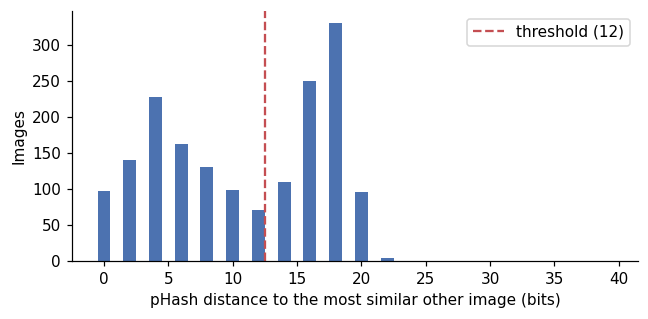




In [9]:
def _bits(h): return np.unpackbits(np.frombuffer(bytes.fromhex(h), dtype=np.uint8))

def hash_matrix(col): return np.stack([_bits(h) for h in col]).astype(np.uint8)

def near_duplicate_pairs(df, pthr=PHASH_THR, dthr=DHASH_THR):
    P, Dh, md5 = hash_matrix(df["phash"]), hash_matrix(df["dhash"]), df["md5"].values
    nn = np.full(len(df), 64)
    pairs = []
    for i in range(len(df) - 1):
        dp = (P[i + 1:] != P[i]).sum(1); dd = (Dh[i + 1:] != Dh[i]).sum(1)
        if len(dp):
            nn[i] = min(nn[i], dp.min()); nn[i + 1:] = np.minimum(nn[i + 1:], dp)
        exact = md5[i + 1:] == md5[i]
        for j in np.where(((dp <= pthr) & (dd <= dthr)) | exact)[0]:
            pairs.append((i, i + 1 + j, int(dp[j]), int(dd[j]), bool(exact[j])))
    pr = pd.DataFrame(pairs, columns=["i", "j", "phash_dist", "dhash_dist", "exact"])
    for c in ["image_id", "class", "src_rel"]:
        pr[c + "_i"] = df[c].values[pr["i"]] if len(pr) else []
        pr[c + "_j"] = df[c].values[pr["j"]] if len(pr) else []
    pr["cross_class"] = pr["class_i"] != pr["class_j"] if len(pr) else []
    return pr, nn

def groups_from_pairs(n, pairs):
    parent = list(range(n))
    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]; a = parent[a]
        return a
    for i, j in zip(pairs["i"], pairs["j"]):
        a, b = find(int(i)), find(int(j))
        if a != b: parent[b] = a
    return np.unique([find(i) for i in range(n)], return_inverse=True)[1]

def contact_sheet(df, pairs, img_dir, out_png, max_pairs=40, title="", keep_order=False):
    if len(pairs) == 0:
        print("no pairs to show"); return
    sel = pairs.head(max_pairs) if keep_order else pairs.sort_values(["exact", "phash_dist"], ascending=[False, True]).head(max_pairs)
    fig, axes = plt.subplots(len(sel), 2, figsize=(5.5, 2.5 * len(sel)))
    axes = np.atleast_2d(axes)
    for r, (_, row) in enumerate(sel.iterrows()):
        for c, k in enumerate(["i", "j"]):
            k = int(row[k]); ax = axes[r, c]
            ax.imshow(Image.open(Path(img_dir) / df["cache_rel"].values[k]).resize((224, 224)))
            sp = f" | {df['split'].values[k]}" if "split" in df and df["split"].values[k] != "all" else ""
            ax.set_title(f"{df['image_id'].values[k]} | {SHORT[df['class'].values[k]]}{sp}\n{Path(df['src_rel'].values[k]).name[:30]}", fontsize=7)
            ax.axis("off")
        lab = row["label"] if "label" in row and isinstance(row["label"], str) else f"pHash {row.phash_dist} / dHash {row.dhash_dist}" + (" EXACT" if row.exact else "")
        axes[r, 0].text(-0.06, 0.5, lab,
                        transform=axes[r, 0].transAxes, rotation=90, va="center", ha="right", fontsize=7)
    fig.suptitle(title, fontsize=9); plt.tight_layout(); plt.savefig(out_png, dpi=120); plt.show(); plt.close(fig)

pairs, nn_dist = near_duplicate_pairs(idx)
idx["dup_group"] = groups_from_pairs(len(idx), pairs)
idx["nn_phash_dist"] = nn_dist
pairs.to_csv(D["audit"] / "duplicate_pairs_original.csv", index=False)

gsize = idx.groupby("dup_group").size()
DUP_HASH = {"exact_duplicate_pairs": int(pairs["exact"].sum()) if len(pairs) else 0,
       "near_duplicate_pairs": int(len(pairs)),
       "cross_class_pairs": int(pairs["cross_class"].sum()) if len(pairs) else 0,
       "images_in_a_duplicate_group": int((idx["dup_group"].map(gsize) > 1).sum()),
       "groups_total": int(idx["dup_group"].nunique()), "largest_group": int(gsize.max()),
       "thresholds": {"phash": PHASH_THR, "dhash": DHASH_THR}}
print("Hash rule only:"); print(json.dumps(DUP_HASH, indent=2))
if DUP_HASH["cross_class_pairs"]:
    print("NOTE: some near-duplicates carry DIFFERENT labels (possible label noise):")
    display(pairs[pairs["cross_class"]][["image_id_i", "class_i", "image_id_j", "class_j", "phash_dist", "exact"]])

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(nn_dist, bins=np.arange(0, 41) - 0.5, color="#4C72B0")
ax.axvline(PHASH_THR + 0.5, color="#C44E52", ls="--", label=f"threshold ({PHASH_THR})")
ax.set_xlabel("pHash distance to the most similar other image (bits)"); ax.set_ylabel("Images"); ax.legend()
plt.tight_layout(); plt.savefig(D["figures"] / "S_nearest_neighbour_phash.png"); plt.show()
# show the 10 closest pairs AND the 30 least similar pairs that were still flagged (the ones that test the threshold)
show = pd.concat([pairs.nsmallest(10, "phash_dist"), pairs[~pairs["exact"]].nlargest(30, ["phash_dist", "dhash_dist"])]).drop_duplicates(["i", "j"])
contact_sheet(idx, show, L["cache448"], D["audit"] / "duplicate_pairs_original.png",
              max_pairs=40, title="Flagged pairs: 10 closest + 30 closest to the threshold")

### 4b. Hash-threshold sensitivity (record)
How many images the hash rule would group at stricter or looser thresholds (kept for the Methods / response letter).

In [10]:
P_all, D_all = hash_matrix(idx["phash"]), hash_matrix(idx["dhash"])
DP = (P_all[:, None, :] != P_all[None, :, :]).sum(2)        # all pairwise pHash distances (1720 x 1720)
DD = (D_all[:, None, :] != D_all[None, :, :]).sum(2)        # all pairwise dHash distances
_md5 = idx["md5"].to_numpy(dtype=str)
MD5_EQ = _md5[:, None] == _md5[None, :]
CLS = idx["label"].to_numpy(dtype=int)
SAME = CLS[:, None] == CLS[None, :]
iu = np.triu_indices(len(idx), 1)

def pairs_from_mask(mask, label=None):
    ii, jj = np.where(np.triu(mask, 1))
    pr = pd.DataFrame({"i": ii, "j": jj, "phash_dist": DP[ii, jj], "dhash_dist": DD[ii, jj], "exact": MD5_EQ[ii, jj]})
    for c in ["image_id", "class", "src_rel"]:
        pr[c + "_i"] = idx[c].values[pr["i"]]; pr[c + "_j"] = idx[c].values[pr["j"]]
    pr["cross_class"] = pr["class_i"] != pr["class_j"]
    return pr

sens = []
for pt, dtr in [(4, 6), (6, 8), (8, 10), (10, 12), (12, 14), (12, 16), (12, 20), (12, 24), (14, 16), (16, 18)]:
    sub = pairs_from_mask(((DP <= pt) & (DD <= dtr)) | MD5_EQ)
    gid = groups_from_pairs(len(idx), sub); gs = np.bincount(gid)
    sens.append({"pHash<=": pt, "dHash<=": dtr, "pairs": len(sub), "images grouped": int((gs[gid] > 1).sum()),
                 "groups": int(len(gs)), "largest group": int(gs.max()),
                 "cross-class pairs": int(sub["cross_class"].sum()),
                 "current": "<-- used" if (pt, dtr) == (PHASH_THR, DHASH_THR) else ""})
SENS = pd.DataFrame(sens)
display(SENS)
SENS.to_csv(D["audit"] / "duplicate_threshold_sensitivity.csv", index=False)

,pHash<=,dHash<=,pairs,images grouped,groups,largest group,cross-class pairs,current
0,4,6,233,420,1501,4,0,
1,6,8,328,589,1413,4,0,
2,8,10,403,730,1341,4,0,
3,10,12,466,833,1287,4,0,
4,12,14,511,894,1250,4,1,
5,12,16,516,903,1245,4,2,<-- used
6,12,20,525,918,1236,4,5,
7,12,24,532,925,1229,4,9,
8,14,16,549,946,1219,7,6,
9,16,18,635,1016,1151,15,39,


### 4c. Deep-feature near-duplicate detection (DINOv2)
Perceptual hashes compare pixel layouts, so the same leaf photographed again after a small camera movement can get a
large hash distance. A self-supervised vision model (DINOv2 ViT-S/14) compares image *content* and is a standard tool
for near-duplicate detection. Every image is embedded and cosine similarities are computed for all pairs.

**Threshold, set from the data (no hand tuning):** two images of *different* classes are certainly different photographs.
For each image we take its highest similarity to any image of another class; the `EMB_Q` = 0.999 quantile of these values is the threshold.
Two images of the **same** class that are more similar than this are treated as near-duplicates
(i.e. more alike than 99.9 % of the closest known-different pairs). A second, combined rule also groups same-class pairs with
cosine ≥ 0.95 **and** pHash ≤ 20 **and** dHash ≤ 20 (same content *and* similar pixel layout: the same leaf photographed again after
a small camera movement). The cell stops if grouping chains into a group larger than `MAX_GROUP`. Final groups = identical files ∪ hash rule ∪ DINOv2 threshold ∪ combined rule.

Check the two sheets: pairs **just above** the threshold should be the same leaf; pairs **just below** should be different leaves.

Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 316MB/s]


dinov2_vits14: (1720, 384) embeddings in 16s on cuda
{
  "rule": "identical MD5, or pHash<=12 and dHash<=16, or same class and dinov2_vits14 cosine>=0.9694550037384033, or same class and cosine>=0.95 and pHash<=20 and dHash<=20",
  "embedding_model": "dinov2_vits14",
  "embedding_quantile": 0.999,
  "embedding_threshold": 0.9694550037384033,
  "exact_duplicate_pairs": 26,
  "pairs_total": 681,
  "pairs_found_by_hash_rule": 516,
  "pairs_added_by_dinov2_threshold": 96,
  "pairs_added_by_combined_rule": 69,
  "cross_class_pairs": 2,
  "images_in_a_duplicate_group": 1075,
  "groups_total": 1112,
  "largest_group": 38,
  "group_size_counts": {
    "1": 645,
    "2": 404,
    "3": 48,
    "4": 6,
    "5": 1,
    "6": 1,
    "7": 4,
    "8": 1,
    "14": 1,
    "38": 1
  }
}


,quantile,cosine threshold,pairs,images grouped,groups,largest group,current
0,0.950,0.960360,1450,1222,863,328,
1,0.980,0.963000,1023,1170,953,249,
2,0.990,0.964324,892,1144,1000,183,
3,0.995,0.965119,848,1135,1017,168,
4,0.999,0.969455,681,1075,1112,38,<-- used


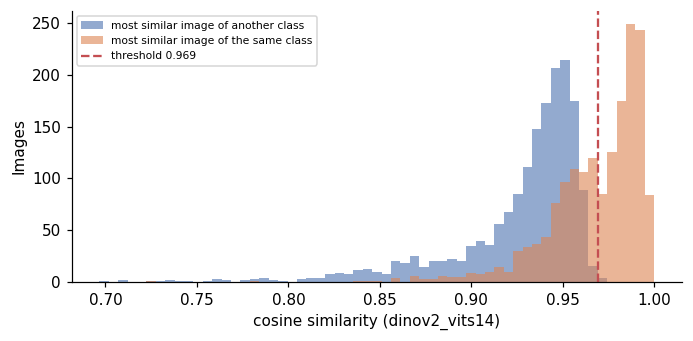

pairs added only by the combined rule: 69


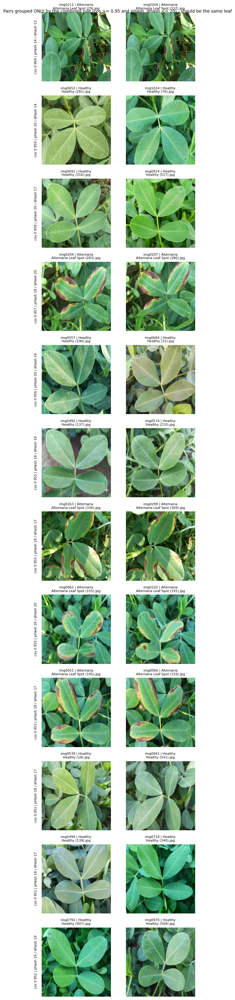

same-class pairs with cosine in [0.969, 0.999): 552


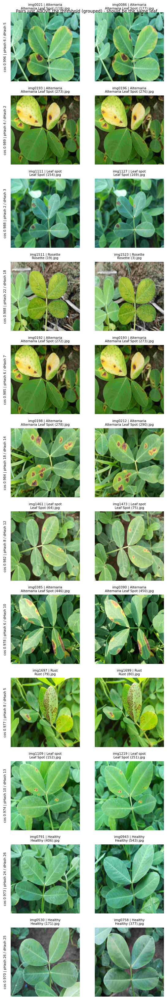

same-class pairs with cosine in [0.939, 0.969): 23882


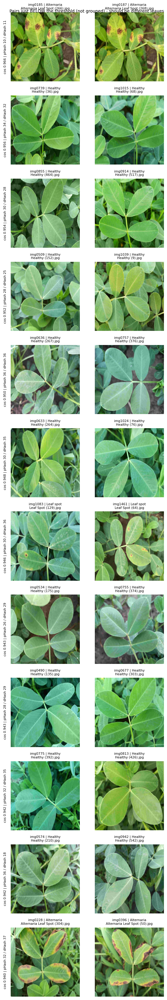

In [11]:
import torch, torchvision
EMB_FILE = D["audit"] / "embeddings.npz"
def load_embedder():
    if os.environ.get("PEANUT_TEST") == "1":
        m = torchvision.models.resnet18(weights=None); m.fc = torch.nn.Identity(); return m, "resnet18-random(test only)"
    if EMB_MODEL.startswith("dinov2"):
        try:
            return torch.hub.load("facebookresearch/dinov2", EMB_MODEL, verbose=False), EMB_MODEL
        except Exception as e:
            print("DINOv2 not available:", e, "-> using ResNet-50 ImageNet features")
    m = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V2); m.fc = torch.nn.Identity()
    return m, "resnet50_imagenet1k_v2"

cached = np.load(EMB_FILE, allow_pickle=True) if EMB_FILE.exists() else None
if cached is not None and list(cached["ids"]) == list(idx["image_id"]) and str(cached["model"]) in (EMB_MODEL, "resnet50_imagenet1k_v2"):
    E, EMB_USED = cached["E"], str(cached["model"]); print("embeddings loaded:", EMB_USED)
else:
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    model, EMB_USED = load_embedder(); model = model.to(dev).eval()
    tf = torchvision.transforms.Compose([torchvision.transforms.Resize((224, 224)), torchvision.transforms.ToTensor(),
                                         torchvision.transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
    feats, t0 = [], time.time()
    with torch.no_grad():
        for k in range(0, len(idx), 64):
            x = torch.stack([tf(Image.open(L["cache448"] / r).convert("RGB")) for r in idx["cache_rel"].values[k:k + 64]]).to(dev)
            feats.append(model(x).float().cpu().numpy())
    E = np.concatenate(feats); E = E / np.linalg.norm(E, axis=1, keepdims=True)
    np.savez(EMB_FILE, E=E, ids=idx["image_id"].values, model=EMB_USED)
    print(f"{EMB_USED}: {E.shape} embeddings in {time.time()-t0:.0f}s on {dev}")

S = E @ E.T
np.fill_diagonal(S, -1)
max_cross = np.where(~SAME, S, -1).max(1)          # each image's most similar image of ANOTHER class
max_same = np.where(SAME, S, -1).max(1)
EMB_THR = float(EMB_TAU) if EMB_TAU is not None else float(np.quantile(max_cross, EMB_Q))
emb_mask = SAME & (S >= EMB_THR)
hash_mask = ((DP <= PHASH_THR) & (DD <= DHASH_THR)) | MD5_EQ
combo_mask = SAME & (S >= COMBO_COS) & (DP <= COMBO_PHASH) & (DD <= COMBO_DHASH)
pairs = pairs_from_mask(hash_mask | emb_mask | combo_mask)
pairs["cos"] = S[pairs["i"], pairs["j"]]
_h, _e, _c = (m[pairs["i"], pairs["j"]] for m in (hash_mask, emb_mask, combo_mask))
pairs["by"] = np.where(_h, "hash", np.where(_e, "dinov2", "dinov2+hash_combined"))
idx["dup_group"] = groups_from_pairs(len(idx), pairs)
idx["max_cos_same_class"], idx["max_cos_other_class"] = max_same, max_cross
pairs.to_csv(D["audit"] / "duplicate_pairs_original.csv", index=False)
gsize = idx.groupby("dup_group").size()
DUP = {"rule": (f"identical MD5, or pHash<={PHASH_THR} and dHash<={DHASH_THR}, or same class and {EMB_USED} cosine>={EMB_THR}, "
               f"or same class and cosine>={COMBO_COS} and pHash<={COMBO_PHASH} and dHash<={COMBO_DHASH}"),
       "embedding_model": EMB_USED, "embedding_quantile": EMB_Q, "embedding_threshold": EMB_THR,
       "exact_duplicate_pairs": int(pairs["exact"].sum()), "pairs_total": int(len(pairs)),
       "pairs_found_by_hash_rule": int((pairs["by"] == "hash").sum()),
       "pairs_added_by_dinov2_threshold": int((pairs["by"] == "dinov2").sum()),
       "pairs_added_by_combined_rule": int((pairs["by"] == "dinov2+hash_combined").sum()),
       "cross_class_pairs": int(pairs["cross_class"].sum()),
       "images_in_a_duplicate_group": int((idx["dup_group"].map(gsize) > 1).sum()),
       "groups_total": int(idx["dup_group"].nunique()), "largest_group": int(gsize.max()),
       "group_size_counts": {int(k): int(v) for k, v in gsize.value_counts().sort_index().items()}}
print(json.dumps(DUP, indent=2))
if DUP["largest_group"] > MAX_GROUP:
    raise SystemExit(f"STOP: the largest duplicate group has {DUP['largest_group']} images (different leaves chained together). "
                     f"Raise EMB_Q (see the sensitivity table) and run again.")

esens = []
for q in [0.95, 0.98, 0.99, 0.995, 0.999]:
    t = float(np.quantile(max_cross, q)); pr_ = pairs_from_mask(hash_mask | combo_mask | (SAME & (S >= t)))
    gid = groups_from_pairs(len(idx), pr_); gs = np.bincount(gid)
    esens.append({"quantile": q, "cosine threshold": t, "pairs": len(pr_), "images grouped": int((gs[gid] > 1).sum()),
                  "groups": int(len(gs)), "largest group": int(gs.max()), "current": "<-- used" if q == EMB_Q and EMB_TAU is None else ""})
ESENS = pd.DataFrame(esens); display(ESENS); ESENS.to_csv(D["audit"] / "embedding_threshold_sensitivity.csv", index=False)

fig, ax = plt.subplots(figsize=(6.4, 3.2))
bins = np.linspace(min(max_cross.min(), max_same.min()), 1, 60)
ax.hist(max_cross, bins=bins, alpha=0.6, label="most similar image of another class", color="#4C72B0")
ax.hist(max_same, bins=bins, alpha=0.6, label="most similar image of the same class", color="#DD8452")
ax.axvline(EMB_THR, color="#C44E52", ls="--", label=f"threshold {EMB_THR:.3f}")
ax.set_xlabel(f"cosine similarity ({EMB_USED})"); ax.set_ylabel("Images"); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(D["figures"] / "S_embedding_similarity.png"); plt.show()

co = pairs[pairs["by"] == "dinov2+hash_combined"]
print(f"pairs added only by the combined rule: {len(co)}")
if len(co):
    b = co.sample(min(12, len(co)), random_state=SEED).sort_values("cos", ascending=False).copy()
    b["label"] = [f"cos {c:.3f} | pHash {p} / dHash {d}" for c, p, d in zip(b["cos"], b["phash_dist"], b["dhash_dist"])]
    contact_sheet(idx, b, L["cache448"], D["audit"] / "embedding_combined_rule_pairs.png", max_pairs=12, keep_order=True,
                  title="Pairs grouped ONLY by the combined rule (cos >= 0.95 and pHash, dHash <= 20) - should be the same leaf")

ii, jj = np.where(np.triu(SAME, 1)); cs = S[ii, jj]
cand = pd.DataFrame({"i": ii, "j": jj, "cos": cs})
for lo, hi, ttl, fn in [(EMB_THR, EMB_THR + 0.03, "just ABOVE the threshold (grouped) - should be the same leaf", "embedding_just_above.png"),
                        (EMB_THR - 0.03, EMB_THR, "just BELOW the threshold (not grouped) - should be different leaves", "embedding_just_below.png")]:
    band = cand[(cand["cos"] >= lo) & (cand["cos"] < hi)]
    print(f"same-class pairs with cosine in [{lo:.3f}, {hi:.3f}): {len(band)}")
    if len(band):
        b = band.sample(min(12, len(band)), random_state=SEED).sort_values("cos", ascending=False)
        b = b.assign(phash_dist=DP[b["i"], b["j"]], dhash_dist=DD[b["i"], b["j"]], exact=MD5_EQ[b["i"], b["j"]])
        b["label"] = [f"cos {c:.3f} | pHash {p} / dHash {d}" for c, p, d in zip(b["cos"], b["phash_dist"], b["dhash_dist"])]
        contact_sheet(idx, b, L["cache448"], D["audit"] / fn, max_pairs=12, title=f"Pairs {ttl}", keep_order=True)

## 5. Audit of the split used in the first submission (R3, R4-6)
Every image in the old `train / val / test` folders is matched back to the original Mendeley file
(byte-identical match first, otherwise the closest perceptual hash). The output answers three questions:

1. **How many images are really in each split?** (Table 3 says 172 test images; the notebooks evaluated 184.)
2. **Did any original image, or a near-duplicate of it, end up in more than one split?** (leakage)
3. **Were any originals not used, or used twice?**

The paper-split images are also cached and zipped, so Notebook 03 can re-train on exactly that split.

In [12]:
PAPER = None
if PAPER_SPLIT_DIR and Path(PAPER_SPLIT_DIR).exists():
    ps = scan_images(PAPER_SPLIT_DIR)
    print(len(ps), "images in the paper split folder")
    PS_CSV = D["splits"] / "index_paper_split.csv"
    PS_ZIP = D["data"] / "paper_split_cache448.zip"
    if PS_CSV.exists() and PS_ZIP.exists():
        ps = pd.read_csv(PS_CSV)
        unzip_to_local(PS_ZIP, L["paper_split"])
    else:
        ps = process_all(ps, L["paper_split"], by_split=True)   # cache layout: <split>/<class>/<file>.jpg
        ps.insert(0, "image_id", [f"ps{i:04d}" for i in range(len(ps))])

    # match every paper-split image to an original
    Po, Pp = hash_matrix(idx["phash"]), hash_matrix(ps["phash"])
    md5_to_orig = dict(zip(idx["md5"], idx["image_id"]))
    best_id, best_d, exact = [], [], []
    for k in range(len(ps)):
        if ps["md5"].values[k] in md5_to_orig:
            best_id.append(md5_to_orig[ps["md5"].values[k]]); best_d.append(0); exact.append(True); continue
        d = (Po != Pp[k]).sum(1); j = int(d.argmin())
        # among near-equal candidates (e.g. two near-duplicate originals) prefer the one with the same file name
        stem = Path(ps["src_rel"].values[k]).stem.lower()
        for c in np.where(d <= d[j] + 2)[0]:
            if Path(idx["src_rel"].values[c]).stem.lower() == stem:
                j = int(c); break
        best_id.append(idx["image_id"].values[j]); best_d.append(int(d[j])); exact.append(False)
    ps["orig_id"], ps["match_phash_dist"], ps["match_exact"] = best_id, best_d, exact
    ps["matched"] = ps["match_exact"] | (ps["match_phash_dist"] <= 6)
    ps["orig_class"] = ps["orig_id"].map(dict(zip(idx["image_id"], idx["class"])))
    ps["orig_dup_group"] = ps["orig_id"].map(dict(zip(idx["image_id"], idx["dup_group"])))

    table3 = pd.crosstab(ps["class"], ps["split"], margins=True, margins_name="Total").reindex(CLASSES + ["Total"])
    print("\nREAL composition of the paper split (compare with Table 3 of the manuscript):")
    display(table3)

    m = ps[ps["matched"]]
    use = m.groupby("orig_id")["split"].agg(lambda s: ",".join(sorted(s)))
    times = m.groupby("orig_id").size()
    grp_splits = m.groupby("orig_dup_group")["split"].agg(lambda s: set(s))
    PAPER = {
        "images_in_paper_split": int(len(ps)),
        "per_split": ps["split"].value_counts().to_dict(),
        "unmatched_images": int((~ps["matched"]).sum()),
        "byte_identical_to_original": int(ps["match_exact"].sum()),
        "label_differs_from_original": int((m["class"] != m["orig_class"]).sum()),
        "originals_used_once": int((times == 1).sum()),
        "originals_used_more_than_once": int((times > 1).sum()),
        "originals_in_more_than_one_split": int(use.apply(lambda s: len(set(s.split(","))) > 1).sum()),
        "originals_never_used": int(len(set(idx["image_id"]) - set(m["orig_id"]))),
        "duplicate_groups_spanning_splits": int(grp_splits.apply(len).gt(1).sum()),
        "test_images_whose_original_or_near_duplicate_is_in_train":
            int(m[m["split"] == "test"]["orig_dup_group"].isin(m[m["split"] == "train"]["orig_dup_group"]).sum()),
        "val_images_whose_original_or_near_duplicate_is_in_train":
            int(m[m["split"] == "val"]["orig_dup_group"].isin(m[m["split"] == "train"]["orig_dup_group"]).sum()),
    }
    print(json.dumps(PAPER, indent=2))
    leak = m[m["orig_dup_group"].isin(grp_splits[grp_splits.apply(len) > 1].index)].sort_values("orig_dup_group")
    leak[["image_id", "split", "class", "src_rel", "orig_id", "match_phash_dist", "orig_dup_group"]].to_csv(D["audit"] / "paper_split_leakage.csv", index=False)
    usage = idx[["image_id", "class", "src_rel"]].assign(used_in=idx["image_id"].map(use).fillna("NOT USED"))
    usage.to_csv(D["audit"] / "original_usage_in_paper_split.csv", index=False)
    print("\nHow each original image was used in the paper split:")
    display(pd.crosstab(usage["class"], usage["used_in"]))
    ps.to_csv(PS_CSV, index=False)
    table3.to_csv(D["audit"] / "paper_split_real_counts.csv")
    if not PS_ZIP.exists():
        z = zip_dir(L["paper_split"], L["tmp"] / PS_ZIP.name, "paper_split")
        copy_to_drive(z, PS_ZIP); z.unlink()
    if len(leak):
        lp = []
        for _, g in leak.groupby("orig_dup_group"):
            a = g.index[0]; others = g[g["split"] != g.loc[a, "split"]]
            if len(others): lp.append((a, others.index[0], int(g.loc[a, "match_phash_dist"]), 0, bool(g["md5"].nunique() == 1)))
        lp = pd.DataFrame(lp, columns=["i", "j", "phash_dist", "dhash_dist", "exact"])
        contact_sheet(ps, lp, L["paper_split"], D["audit"] / "paper_split_leakage.png", max_pairs=20,
                      title="Same original / near-duplicate in two splits")
else:
    print("Paper split folder not found - step 5 skipped. (Set PAPER_SPLIT_DIR in Settings if it is elsewhere.)")

Paper split folder not found - step 5 skipped. (Set PAPER_SPLIT_DIR in Settings if it is elsewhere.)


## 6. Save the index and zip the image cache to Drive
The full-size originals stay only in `00_raw/` (the zip exactly as Mendeley serves it), to save Drive space.
One small zip is stored in `01_data/`:
* `groundnut_v2_cache448.zip` — the 448 × 448 copies the training notebooks use. Training notebooks copy this zip
  to the Colab disk and unzip it there, so training never reads images from Drive.

In [13]:
idx.to_csv(INDEX_CSV, index=False)
print("index saved:", INDEX_CSV)

if not CACHE_ZIP.exists():
    z = zip_dir(L["cache448"], L["tmp"] / CACHE_ZIP.name, "cache448")
    copy_to_drive(z, CACHE_ZIP); z.unlink()
for p in sorted(D["data"].glob("*.zip")):
    print(f"{p.name:<36} {p.stat().st_size/1e6:10.1f} MB")

index saved: /content/drive/MyDrive/Peanut_Revision/02_splits/index_original.csv
groundnut_v2_cache448.zip                 128.8 MB


## 7. Stratified group 5-fold cross-validation splits (R3-5, R4-3, R4-6)
* **Outer split:** `StratifiedGroupKFold(5)`: each fold is the test set once (≈ 20 % of the images); class proportions are kept,
  and duplicate groups never cross folds.
* **Inner split:** inside the remaining 80 %, one `StratifiedGroupKFold(8)` fold (= 10 % of all images) is the **validation**
  set, used only to pick the best epoch. The rest (≈ 70 %) is for training.
* Every image is tested exactly once per repeat, so predictions can be pooled over folds.

`cv_splits.csv` is the file we deposit on Zenodo; it lets anyone reproduce the exact folds.

In [14]:
from sklearn.model_selection import StratifiedGroupKFold

CV_CSV = D["splits"] / "cv_splits.csv"
CV_META = D["splits"] / "cv_splits_meta.json"
cv_meta = {"phash_thr": PHASH_THR, "dhash_thr": DHASH_THR, "emb_model": EMB_USED, "emb_q": EMB_Q, "emb_thr": EMB_THR,
           "combo": [COMBO_COS, COMBO_PHASH, COMBO_DHASH],
           "k": K_FOLDS, "repeats": N_REPEATS,
           "inner_val_folds": INNER_VAL_FOLDS, "seed": SEED, "n_groups": int(idx["dup_group"].nunique())}
if CV_CSV.exists() and CV_META.exists() and json.loads(CV_META.read_text()) == cv_meta:
    cv = pd.read_csv(CV_CSV); print("Loaded existing", CV_CSV)
else:
    if CV_CSV.exists() and CV_META.exists():
        old = json.loads(CV_META.read_text())
        tag = f"split_pHash{old.get('phash_thr')}_dHash{old.get('dhash_thr')}" + ("_emb" if old.get("emb_model") else "")
        print("Settings or duplicate groups changed -> rebuilding the cross-validation splits.")
        # keep the old splits, and move results trained on them out of the way (renaming on Drive sends nothing to the bin)
        shutil.copyfile(CV_CSV, D["splits"] / f"cv_splits__{tag}.csv")
        shutil.copyfile(CV_META, D["splits"] / f"cv_splits_meta__{tag}.json")
        for key in ["results", "models", "checkpoints"]:
            src = D[key]
            if src.exists() and any(src.iterdir()):
                dst, k = src.with_name(f"{src.name}__archive_{tag}"), 2
                while dst.exists():
                    dst, k = src.with_name(f"{src.name}__archive_{tag}_{k}"), k + 1
                src.rename(dst); src.mkdir()
                print(f"  {src.name}/ was trained on the old splits -> moved to {dst.name}/ (kept, not deleted)")
    y, g = idx["label"].values, idx["dup_group"].values
    rows = []
    for r in range(N_REPEATS):
        outer = StratifiedGroupKFold(n_splits=K_FOLDS, shuffle=True, random_state=SEED + r)
        for f, (trval, te) in enumerate(outer.split(np.zeros(len(y)), y, g)):
            inner = StratifiedGroupKFold(n_splits=INNER_VAL_FOLDS, shuffle=True, random_state=SEED + 100 * r + f)
            tr_i, va_i = next(inner.split(np.zeros(len(trval)), y[trval], g[trval]))
            role = np.empty(len(y), dtype=object)
            role[trval[tr_i]], role[trval[va_i]], role[te] = "train", "val", "test"
            rows.append(pd.DataFrame({"repeat": r, "fold": f, "image_id": idx["image_id"], "role": role}))
    cv = pd.concat(rows, ignore_index=True)
    cv.to_csv(CV_CSV, index=False)
    CV_META.write_text(json.dumps(cv_meta, indent=2))

# integrity checks
cvx = cv.merge(idx[["image_id", "class", "dup_group"]], on="image_id")
for (r, f), s in cvx.groupby(["repeat", "fold"]):
    assert s.groupby("dup_group")["role"].nunique().max() == 1, "a duplicate group crosses train/val/test!"
for r, s in cvx[cvx["role"] == "test"].groupby("repeat"):
    assert s["image_id"].is_unique and len(s) == len(idx), "each image must be tested exactly once per repeat"
print("checks passed: duplicate groups never cross roles; every image is tested exactly once per repeat")

fold_table = cvx[cvx["repeat"] == 0].pivot_table(index=["fold", "role"], columns="class", values="image_id",
                                                  aggfunc="count", fill_value=0)[CLASSES]
fold_table["Total"] = fold_table.sum(1)
display(fold_table)
fold_table.to_csv(D["tables"] / "Table_CV_fold_composition.csv")
mean_table = fold_table.groupby("role").mean().round(1).reindex(["train", "val", "test"])
mean_table.to_csv(D["tables"] / "Table3_new_mean_images_per_fold.csv")
print("Mean images per fold (this replaces Table 3):"); display(mean_table)

checks passed: duplicate groups never cross roles; every image is tested exactly once per repeat


class       Alternaria leaf spot  Healthy  Leaf spot (early and late)  \
fold role                                                               
0    test                     85      146                          91   
     train                   323      400                         317   
     val                      42       54                          42   
1    test                     86      102                          90   
     train                   323      453                         321   
     val                      41       45                          39   
2    test                     90      126                          81   
     train                   317      429                         330   
     val                      43       45                          39   
3    test                     89      120                          96   
     train                   317      433                         317   
     val                      44       47                          37   
4    test                    100      106                          92   
     train                   310      434                         321   
     val                      40       60                          37   

class       Rosette  Rust  Total  
fold role                         
0    test        18    26    366  
     train       74    86   1200  
     val          8     8    154  
1    test        18    22    318  
     train       71    87   1255  
     val         11    11    147  
2    test        24    20    341  
     train       66    90   1232  
     val         10    10    147  
3    test        18    31    354  
     train       73    77   1217  
     val          9    12    149  
4    test        22    21    341  
     train       71    88   1224  
     val          7    11    155

Mean images per fold (this replaces Table 3):


class,Alternaria leaf spot,Healthy,Leaf spot (early and late),Rosette,Rust,Total
role,,,,,,
train,318.0,429.8,321.2,71.0,85.6,1225.6
val,42.0,50.2,38.8,9.0,10.4,150.4
test,90.0,120.0,90.0,20.0,24.0,344.0


### 7b. Leakage check: the most similar training image of every test image (R4-6)
For every test image, the most similar image in the same fold's training + validation data is found with DINOv2
(cosine similarity) and with the hashes. No test–train/val pair may meet the grouping rule (checked for **all** pairs).
The first sheet shows the 24 most similar test–training pairs over all folds (by DINOv2): they should be **different leaves**.
This is the evidence for Reviewer 4 that near-duplicates do not cross partitions.

{
  "test_images_checked": 1720,
  "test_trainval_pairs_meeting_the_grouping_rule": 0,
  "nearest_cosine_quantiles": {
    "0.5": 0.9490727186203003,
    "0.95": 0.966226801276207,
    "0.99": 0.9687371093034745,
    "1.0": 0.9698953628540039
  },
  "nearest_phash_quantiles": {
    "0.0": 10.0,
    "0.01": 12.0,
    "0.05": 14.0,
    "0.5": 18.0
  },
  "rule": "identical MD5, or pHash<=12 and dHash<=16, or same class and dinov2_vits14 cosine>=0.9694550037384033, or same class and cosine>=0.95 and pHash<=20 and dHash<=20"
}


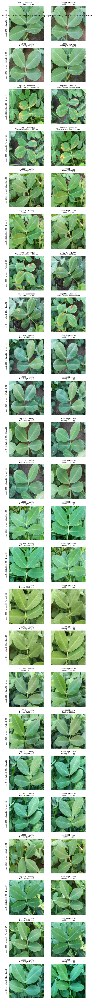

In [15]:
pid = {iid: k for k, iid in enumerate(idx["image_id"])}
RULE = hash_mask | emb_mask | combo_mask
nn_rows, n_viol = [], 0
for (r, f), s in cv.groupby(["repeat", "fold"]):
    te = np.array([pid[i] for i in s.loc[s["role"] == "test", "image_id"]])
    tv = np.array([pid[i] for i in s.loc[s["role"] != "test", "image_id"]])
    n_viol += int(RULE[np.ix_(te, tv)].sum())
    Ssub = S[np.ix_(te, tv)]; jc = Ssub.argmax(1)
    hsub = DP[np.ix_(te, tv)] * 100 + DD[np.ix_(te, tv)]; jh = hsub.argmin(1)
    for a in range(len(te)):
        b, bh = tv[jc[a]], tv[jh[a]]
        nn_rows.append((r, f, te[a], b, float(S[te[a], b]), int(DP[te[a], b]), int(DD[te[a], b]), bool(MD5_EQ[te[a], b]),
                        bh, int(DP[te[a], bh]), int(DD[te[a], bh])))
nn = pd.DataFrame(nn_rows, columns=["repeat", "fold", "i", "j", "cos", "phash_dist", "dhash_dist", "exact",
                                    "j_hash", "phash_dist_hash_nn", "dhash_dist_hash_nn"])
for c in ["image_id", "class", "src_rel"]:
    nn[c + "_i"] = idx[c].values[nn["i"]]; nn[c + "_j"] = idx[c].values[nn["j"]]
nn.to_csv(D["audit"] / "nearest_trainval_image_for_each_test_image.csv", index=False)
LEAK_CHECK = {"test_images_checked": int(len(nn)),
              "test_trainval_pairs_meeting_the_grouping_rule": n_viol,
              "nearest_cosine_quantiles": {str(k): float(v) for k, v in nn["cos"].quantile([0.5, 0.95, 0.99, 1.0]).items()},
              "nearest_phash_quantiles": {str(k): float(v) for k, v in nn["phash_dist_hash_nn"].quantile([0, 0.01, 0.05, 0.5]).items()},
              "rule": DUP["rule"]}
print(json.dumps(LEAK_CHECK, indent=2))
assert n_viol == 0, "grouping failed: a near-duplicate crosses partitions"
show = nn.sort_values("cos", ascending=False).head(24).copy()
show["label"] = [f"cos {c:.3f} | pHash {p} / dHash {d}" for c, p, d in zip(show["cos"], show["phash_dist"], show["dhash_dist"])]
contact_sheet(idx, show, L["cache448"], D["audit"] / "closest_test_train_pairs_after_grouping.png", max_pairs=24, keep_order=True,
              title="24 most similar test-training pairs after grouping (DINOv2) - should be different leaves")

## 8. Dataset figures for the manuscript (300 dpi PNG + vector PDF)

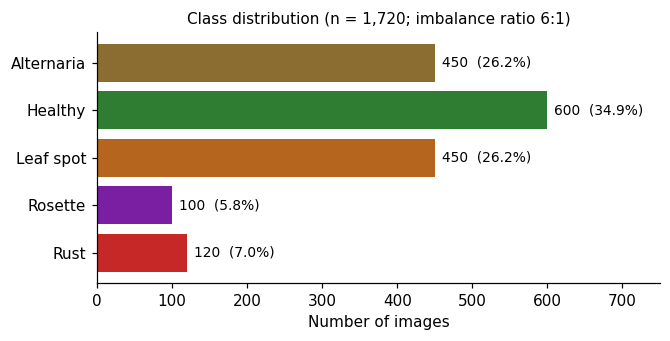

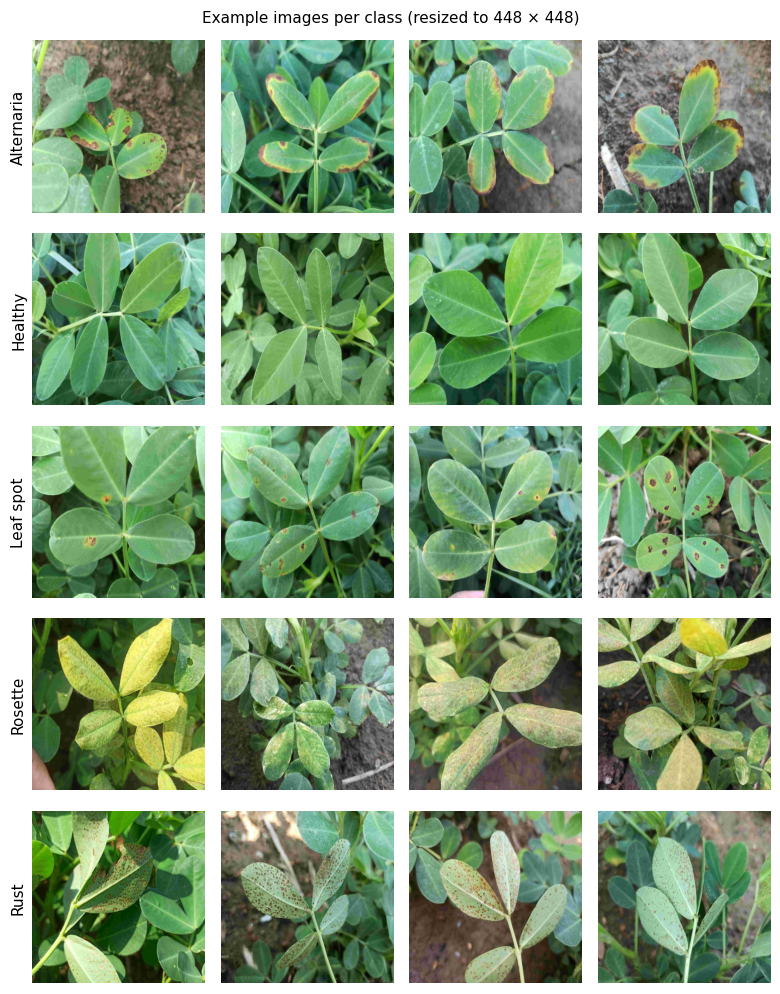

In [16]:
COLORS = {"Alternaria leaf spot": "#8C6D31", "Healthy": "#2E7D32", "Leaf spot (early and late)": "#B5651D",
          "Rosette": "#7B1FA2", "Rust": "#C62828"}

# Figure: class distribution
cnt = idx["class"].value_counts().reindex(CLASSES)
fig, ax = plt.subplots(figsize=(6.2, 3.2))
bars = ax.barh([SHORT[c] for c in CLASSES][::-1], cnt.values[::-1], color=[COLORS[c] for c in CLASSES][::-1])
for b, v in zip(bars, cnt.values[::-1]):
    ax.text(v + cnt.max() * 0.015, b.get_y() + b.get_height() / 2, f"{v}  ({100*v/cnt.sum():.1f}%)", va="center", fontsize=9)
ax.set_xlabel("Number of images"); ax.set_xlim(0, cnt.max() * 1.25)
ax.set_title(f"Class distribution (n = {cnt.sum():,}; imbalance ratio {cnt.max()/cnt.min():.0f}:1)", fontsize=10)
plt.tight_layout()
for ext in ["png", "pdf"]: plt.savefig(D["figures"] / f"Fig_dataset_class_distribution.{ext}")
plt.show()

# Figure: example images (4 per class, random but fixed)
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(len(CLASSES), 4, figsize=(7.2, 9.2))
for r, c in enumerate(CLASSES):
    sel = idx[idx["class"] == c].sample(4, random_state=SEED)
    for k, rel in enumerate(sel["cache_rel"]):
        ax = axes[r, k]; ax.imshow(Image.open(L["cache448"] / rel)); ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values(): s.set_visible(False)
    axes[r, 0].set_ylabel(SHORT[c], fontsize=10)
plt.suptitle("Example images per class (resized to 448 × 448)", fontsize=10)
plt.tight_layout()
for ext in ["png", "pdf"]: plt.savefig(D["figures"] / f"Fig_dataset_examples.{ext}")
plt.show()

## 9. Report and results zip
`NB01_report.json` and `NB01_report.md` summarise everything above. `NB01_results.zip` contains the report, tables,
figures and audit files (no images). Send me the zip.

In [17]:
def _md_table(t):
    try: return t.to_markdown()
    except Exception: return "```\n" + t.to_string() + "\n```"

REPORT = {
    "dataset": {"doi": DATASET_DOI, "url": DATASET_URL, "version": DATASET_VERSION, "raw_zip_sha256": RAW_SHA256,
                "cache_zip_sha256": sha256_file(CACHE_ZIP)},
    "completeness": {"counts": counts["found"].to_dict(), "published": EXPECTED_COUNTS,
                     "matches_published": COMPLETE, "unreadable": n_unreadable},
    "acquisition_metadata": meta,
    "duplicates": DUP,
    "duplicates_hash_rule_only": DUP_HASH,
    "embedding_threshold_sensitivity": ESENS.drop(columns="current").to_dict("records"),
    "duplicate_threshold_sensitivity": SENS.drop(columns="current").to_dict("records"),
    "leakage_check": LEAK_CHECK,
    "paper_split_audit": PAPER,
    "cv": {"k": K_FOLDS, "repeats": N_REPEATS, "inner_val_folds": INNER_VAL_FOLDS, "seed": SEED,
           "mean_images_per_fold": mean_table.to_dict()},
    "environment": ENV,
}
(D["audit"] / "NB01_report.json").write_text(json.dumps(REPORT, indent=2, default=str))

lines = ["# Notebook 01 report", "", f"Run: {ENV['run_at']}", "",
         "## Dataset", f"- DOI {DATASET_DOI} (version {DATASET_VERSION}); raw zip SHA-256 `{RAW_SHA256[:16]}...`",
         f"- Images found: {int(counts.loc['Total','found'])} (published: {sum(EXPECTED_COUNTS.values())}); matches published counts: **{COMPLETE}**; unreadable: {n_unreadable}",
         "", "## Acquisition metadata", "```", json.dumps(meta, indent=2, default=str), "```",
         "", "## Duplicates (final rule)", "```", json.dumps(DUP, indent=2), "```",
         "", "## Threshold sensitivity", _md_table(SENS.set_index("pHash<=")),
         "", "## Paper split audit", "```", json.dumps(PAPER, indent=2) if PAPER else "folder not available", "```",
         "", "## Mean images per CV fold", _md_table(mean_table)]
(D["audit"] / "NB01_report.md").write_text("\n".join(lines))

# ---- research log: exact values only (integers, full-precision floats, full checksums) ----
def _md(t):
    try: return t.to_markdown()
    except Exception: return "```\n" + t.to_string() + "\n```"
fold_exact = cvx.pivot_table(index=["repeat", "fold", "role"], columns="class", values="image_id", aggfunc="count", fill_value=0)[CLASSES]
fold_exact["Total"] = fold_exact.sum(1)
mean_exact = fold_exact.groupby("role").mean().reindex(["train", "val", "test"])
RL = [f"# Research log — Notebook 01 (run {ENV['run_at']})", "",
      "All values are copied programmatically from the run (no rounding).", "",
      "## Dataset", f"- DOI: {DATASET_DOI} (version {DATASET_VERSION})",
      f"- Raw zip SHA-256: {RAW_SHA256}", f"- Cache zip SHA-256: {sha256_file(CACHE_ZIP)}",
      f"- Images found per class: {counts['found'].to_dict()}", f"- Unreadable files: {n_unreadable}",
      f"- Byte-identical copies (images whose MD5 equals an earlier image): {n_md5_dup}",
      f"- Acquisition metadata: {json.dumps(meta, default=str)}", "",
      f"## Near-duplicate grouping — final rule: {DUP['rule']}",
      "```", json.dumps(DUP, indent=2), "```", "", "### Hash rule alone", "```", json.dumps(DUP_HASH, indent=2), "```", "",
      "### Hash threshold sensitivity", _md(SENS.set_index("pHash<=")), "",
      "### Embedding threshold sensitivity (cosine thresholds are exact values)", _md(ESENS.set_index("quantile")), "",
      "## Cross-validation folds (exact image counts)", _md(fold_exact), "",
      "### Mean per fold (exact float)", "```", mean_exact.to_dict().__repr__(), "```", "",
      "## Leakage check (nearest training/validation image of every test image)", "```", json.dumps(LEAK_CHECK, indent=2), "```", "",
      "## Old paper split audit", "```", json.dumps(PAPER, indent=2) if PAPER else "folder not available", "```", "",
      "## Environment", "```", json.dumps(ENV, indent=2), "```"]
(D["logs"] / "research_log_NB01.md").write_text("\n".join(RL))
print("research log written:", D["logs"] / "research_log_NB01.md")

res_zip = L["tmp"] / "NB01_results.zip"
with zipfile.ZipFile(res_zip, "w", zipfile.ZIP_DEFLATED) as z:
    for folder in ["audit", "tables", "figures", "logs"]:
        for p in D[folder].glob("*"):
            if p.is_file() and p.suffix in {".json", ".md", ".csv", ".png", ".pdf", ".txt"} and not p.name.startswith("NB01_results"):
                z.write(p, f"{folder}/{p.name}")
    for name in ["cv_splits.csv", "index_original.csv", "index_paper_split.csv"]:
        if (D["splits"] / name).exists(): z.write(D["splits"] / name, f"splits/{name}")
copy_to_drive(res_zip, D["audit"] / "NB01_results.zip")
print("\n".join(lines))
print(f"\nSaved: {D['audit'] / 'NB01_results.zip'}  ({res_zip.stat().st_size/1e6:.1f} MB)")
if IN_COLAB:
    from google.colab import files
    files.download(str(res_zip))

research log written: /content/drive/MyDrive/Peanut_Revision/09_logs/research_log_NB01.md
# Notebook 01 report

Run: 2026-10-31T09:02:17

## Dataset
- DOI 10.17632/x6x5jkk873.2 (version 2); raw zip SHA-256 `314dc4152782e9ee...`
- Images found: 1720 (published: 1720); matches published counts: **True**; unreadable: 0

## Acquisition metadata
```
{
  "resolutions": {
    "4624x3472": 1720
  },
  "camera": {
    "unknown": 1720
  },
  "orientation_tags": {
    "1": 1720
  },
  "images_with_capture_date": 0,
  "capture_date_first": null,
  "capture_date_last": null,
  "distinct_capture_days": 0,
  "capture_hour_range": null,
  "flash_values": {
    "": 1720
  }
}
```

## Duplicates (final rule)
```
{
  "rule": "identical MD5, or pHash<=12 and dHash<=16, or same class and dinov2_vits14 cosine>=0.9694550037384033, or same class and cosine>=0.95 and pHash<=20 and dHash<=20",
  "embedding_model": "dinov2_vits14",
  "embedding_quantile": 0.999,
  "embedding_threshold": 0.9694550037384033,
  "ex

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>